In [10]:
from ModelTrainingFile import ModelTraining, PoseNet
import torch
import torchvision.models as models
from torchvision import transforms
from PIL import Image

In [4]:
model = PoseNet()

In [7]:
model.load_state_dict(torch.load('trained_models/posev00254.pth', map_location='cpu'))


<All keys matched successfully>

In [8]:
model.eval()

PoseNet(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (

In [99]:
from resizeImage import transform_data
image = Image.open('image.jpeg')
image, _, reverse1 = transform_data('image.jpeg', [])




0: 512x640 3 persons, 3 ties, 937.3ms
Speed: 5.0ms preprocess, 937.3ms inference, 2.0ms postprocess per image at shape (1, 3, 512, 640)


In [100]:
from torchvision import transforms

transform = transforms.Compose([
    # transforms.Resize(224),  # Resize the shortest side to 256
    # transforms.CenterCrop(224),  # Crop the center to 256x256 if the image is larger than 224x224
    # transforms.Pad((16, 16)),  # Pad the image to reach 224x224
    transforms.ToTensor(),  # Convert to tensor
])


In [101]:
image_tensor = transform(image).unsqueeze(0)  # unsqueeze to add artificial first dimension for batch size
with torch.no_grad():  # Disable gradient computation during inference
    output = model(image_tensor)

print(output)

tensor([[0.5109, 0.8038, 0.5150, 0.6644, 0.5123, 0.5143, 0.5298, 0.5146, 0.5349, 0.6689, 0.5353, 0.7977, 0.5214, 0.5155, 0.5143, 0.2833, 0.5155, 0.2608, 0.5242, 0.1070, 0.4908, 0.4171, 0.4933, 0.3857, 0.5027, 0.2832, 0.5266, 0.2806, 0.5316, 0.3716, 0.5382, 0.4023]])


In [102]:
import cv2
image = cv2.imread('image.jpeg')


In [103]:
coordinates = output[0].numpy()
coordinates = coordinates.tolist()

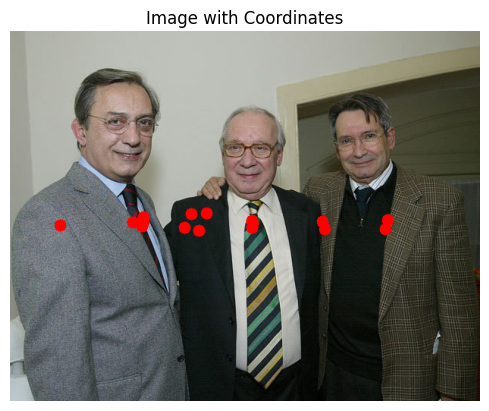

In [110]:
from matplotlib import pyplot as plt
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Your interleaved list of coordinates

# Loop through the list and extract x and y coordinates
for i in range(0, len(coordinates), 2):  # Step of 2 to get pairs of coordinates
    y = coordinates[i] * 488    # x coordinate
    x = coordinates[i + 1] * 620 # y coordinate
    
    cv2.circle(image_rgb, (round(x), round(y)), radius=8, color=(255, 0, 0), thickness=-1)  # Red points

# Display the image with points using Matplotlib
plt.imshow(image_rgb)
plt.title("Image with Coordinates")
plt.axis('off')  # Hide axes for better visualization
plt.show()